# Data Preprocessing - TP Solution

Ouahiba Lebbihi

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, MinMaxScaler, LabelEncoder, OrdinalEncoder

pd.set_option('display.max_columns', None)

In [2]:
url = 'https://raw.githubusercontent.com/BouhamedMohammedMounir/Machine-learning-course/master/salaries.csv'
df = pd.read_csv(url)

### 1. Show the dimensions

In [3]:
print('Shape:', df.shape)

Shape: (152959, 11)


### 2. Display the first five rows

In [4]:
df.head()

,work_year,experience_level,employment_type,job_title,salary,salary_currency,salary_in_usd,employee_residence,remote_ratio,company_location,company_size
0,2025.0,EX,FT,Head of Data,348516.0,USD,NaN,US,0.0,US,M
1,2025.0,EX,FT,Head of Data,232344.0,USD,232344.0,US,0.0,NaN,M
2,2025.0,SE,NaN,Data Scientist,145400.0,USD,145400.0,US,NaN,NaN,M
3,2025.0,SE,FT,Data Scientist,81600.0,NaN,81600.0,US,0.0,NaN,M
4,2025.0,MI,FT,Engineer,160000.0,USD,160000.0,US,100.0,US,M


### 3. Identify duplicated rows

In [5]:
print('Duplicated rows:', df.duplicated().sum())

Duplicated rows: 43184


### 4. Remove duplicates

In [6]:
df = df.drop_duplicates().reset_index(drop=True)
print('New shape:', df.shape)

New shape: (109775, 11)


### 5. Calculate missing-value percentages

In [7]:
missing_pct = (df.isnull().sum() / len(df)) * 100
missing_pct.sort_values(ascending=False).round(2)

company_location      81.90
salary_in_usd          9.93
salary                 7.56
company_size           6.55
remote_ratio           6.43
experience_level       6.36
employment_type        5.28
employee_residence     5.26
job_title              4.56
salary_currency        4.00
work_year              2.65
dtype: float64

### 6. Remove columns with at least 70% missing values

In [8]:
cols_to_drop = missing_pct[missing_pct >= 70].index.tolist()
df = df.drop(columns=cols_to_drop)
print('Removed columns:', cols_to_drop)
print('Shape:', df.shape)

Removed columns: ['company_location']
Shape: (109775, 10)


### 7. Compare the two row-deletion methods using separate copies

In [9]:
complete_rows = df.dropna()
salary_rows = df.dropna(subset=['salary_in_usd'])

print('Before removal:', len(df))
print('After removing all incomplete rows:', len(complete_rows))
print('After removing rows missing salary_in_usd:', len(salary_rows))

Before removal: 109775
After removing all incomplete rows: 57833
After removing rows missing salary_in_usd: 98879


### 8. Fill numerical missing values with the median

In [10]:
num_cols = df.select_dtypes(include=np.number).columns

for col in num_cols:
    df[col] = df[col].fillna(df[col].median())

df[num_cols].isnull().sum()

work_year        0
salary           0
salary_in_usd    0
remote_ratio     0
dtype: int64

### 9. Fill categorical missing values with the mode

In [11]:
cat_cols = df.select_dtypes(include='object').columns

for col in cat_cols:
    if df[col].isnull().any():
        df[col] = df[col].fillna(df[col].mode()[0])

df[cat_cols].isnull().sum()

experience_level      0
employment_type       0
job_title             0
salary_currency       0
employee_residence    0
company_size          0
dtype: int64

### 10. Detect salary outliers using IQR

In [12]:
q1 = df['salary_in_usd'].quantile(0.25)
q3 = df['salary_in_usd'].quantile(0.75)
iqr = q3 - q1

lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

outliers = df[(df['salary_in_usd'] < lower_bound) | (df['salary_in_usd'] > upper_bound)]
print('Lower bound:', lower_bound)
print('Upper bound:', upper_bound)
print('Number of outliers:', len(outliers))

Lower bound: -19072.5
Upper bound: 315443.5
Number of outliers: 4493


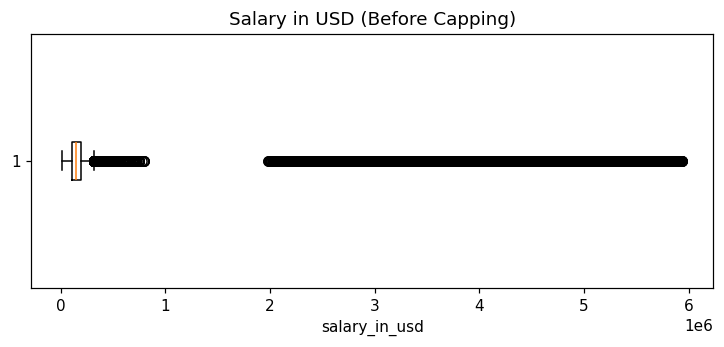

In [13]:
plt.figure(figsize=(8, 3))
plt.boxplot(df['salary_in_usd'], vert=False)
plt.title('Salary in USD (Before Capping)')
plt.xlabel('salary_in_usd')
plt.show()

### 11. Cap salary values using those limits

In [14]:
df['salary_in_usd'] = df['salary_in_usd'].clip(lower=lower_bound, upper=upper_bound)

outliers_after = df[(df['salary_in_usd'] < lower_bound) | (df['salary_in_usd'] > upper_bound)]
print('Outliers after capping:', len(outliers_after))
df['salary_in_usd'].describe()

Outliers after capping: 0


count    109775.000000
mean     153887.623498
std       67305.427093
min       15000.000000
25%      106371.000000
50%      144000.000000
75%      190000.000000
max      315443.500000
Name: salary_in_usd, dtype: float64

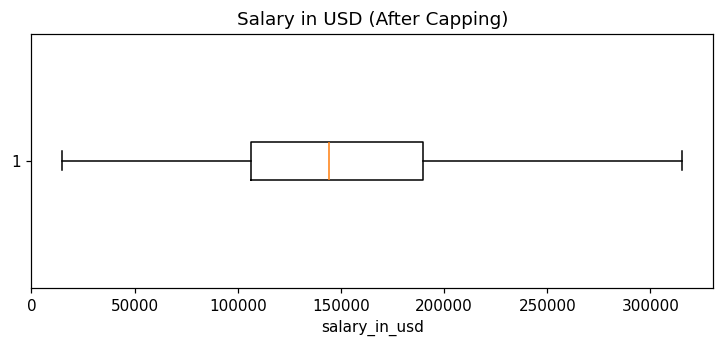

In [15]:
plt.figure(figsize=(8, 3))
plt.boxplot(df['salary_in_usd'], vert=False)
plt.title('Salary in USD (After Capping)')
plt.xlabel('salary_in_usd')
plt.show()

### 12. Standardize numerical variables

In [16]:
scaler = StandardScaler()
df[num_cols] = scaler.fit_transform(df[num_cols])
df[num_cols].head()

,work_year,salary,salary_in_usd,remote_ratio
0,0.806244,0.262075,-0.146907,-0.516681
1,0.806244,0.037477,1.165682,-0.516681
2,0.806244,-0.130613,-0.126107,-0.516681
3,0.806244,-0.253959,-1.074029,-0.516681
4,0.806244,-0.102387,0.090816,1.943730


### 13. One-hot encode `employment_type`

In [17]:
df = pd.get_dummies(df, columns=['employment_type'], dtype=int)
print('Remaining missing values:', int(df.isnull().sum().sum()))
print('Final shape:', df.shape)
df.head()

Remaining missing values: 0
Final shape: (109775, 13)


,work_year,experience_level,job_title,salary,salary_currency,salary_in_usd,employee_residence,remote_ratio,company_size,employment_type_CT,employment_type_FL,employment_type_FT,employment_type_PT
0,0.806244,EX,Head of Data,0.262075,USD,-0.146907,US,-0.516681,M,0,0,1,0
1,0.806244,EX,Head of Data,0.037477,USD,1.165682,US,-0.516681,M,0,0,1,0
2,0.806244,SE,Data Scientist,-0.130613,USD,-0.126107,US,-0.516681,M,0,0,1,0
3,0.806244,SE,Data Scientist,-0.253959,USD,-1.074029,US,-0.516681,M,0,0,1,0
4,0.806244,MI,Engineer,-0.102387,USD,0.090816,US,1.943730,M,0,0,1,0
